# PHYS20762 
# Project 2- Numerical Integration of Differential Equations
**The Damped Harmonic Oscillator**

This project sets out to:

- Find 4 solutions for 4 numerical methods (Euler, Improved Euler, Verlet and Euler-Cromer) assuming no external force e.g. F = 0
- Plot each numerical method
- Explore effects of varying time-step and 1/2, double and exactly critical damping values.
- Further investigation into the behaviour of the system under forced oscillations (a kick or external sinusoidal forces)
- Discuss symplectic methods and its impact on accuracy at b=0.

To stretch myself and as an extension:
- Incorporate the Runge-Kutta method into the report as comparison (as a more accurate 4th-order model)
- Explore under varying damping constant
- Investigate the system under varying frequency above and below natural frequency and observe resonance.

Equation of motion for the mass spring constant under no force:
$$ m a = - k x + b v $$
for some mass $m$, spring constant $k$ and damping constant $b$. Here, velocity and acceleration are
$v = \frac{\textrm{d} x}{\textrm{d} t}$ and $a = \frac{\textrm{d} v}{\textrm{d} t}$, and system is subject to some initial conditions 𝑥(𝑡=0) and 𝑣(𝑡=0). 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, Dropdown

m = 2.47 # kg
k = 1.15 # kg . s-2
b = 0.3 # kg . s-1

# Choose integrating time (in s)
T = 80 # s
# Choose the step size (in s)
h = 0.05 # s

#Initial conditions
x_0 = 0 # m
v_0 = -1 # m.s-1

Assuming h is a small *time step*, the **Euler's Method** is 
$$x_{i+1} = x_{i} + h \cdot v_{i}$$ 
$$v_{i+1} = v_{i} + h \cdot a_{i}$$    
where  
$$a_{i} = -(k/m) x_{i} -(b/m) v_{i}$$ Here $i$ labels the number of steps taken (each of size $h$ in time). This allows us to model the system over some specified time from $t =0$ to $t=T$. 

In [2]:
def Euler(T, h, x_0, v_0, k, m, b):
    # number of steps
    nsteps = int(T/h)
    # Empty arrays
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    t = np.zeros(nsteps)
    # Initial conditions
    x[0] = x_0 # in m
    v[0] = v_0 # in m. s-1

    for i in range(nsteps - 1):
        accel = -(k/m)*x[i] - (b/m)*v[i]
        x[i+1] = x[i] + (v[i] * h)
        v[i+1] = v[i] + (accel * h)
        t[i+1] = t[i] + h

    return x, v, t

Assuming h is a small *time step*, the **Improved Euler Method** is 
$$x_{i+1} = x_i + \frac{h}{2}\left(v_i + v_i^*\right)$$ 
$$v_{i+1} = v_i + \frac{h}{2}\left(a_i + a_i^*\right)$$    
where the predicted values are  
$$x_i^* = x_i + h \cdot v_i, \quad v_i^* = v_i + h \cdot a_i$$  
and  
$$a_i = -(k/m)x_i -(b/m)v_i, \quad a_i^* = -(k/m)x_i^* -(b/m)v_i^*.$$  

Here $i$ labels the number of steps taken (each of size $h$ in time). This allows us to model the system over some specified time from $t = 0$ to $t = T$, with improved accuracy by averaging the slopes at the beginning and end of each step.

In [3]:
def Improved_Euler(T, h, x_0, v_0, k, m, b):
    nsteps = int(T/h)
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    t = np.zeros(nsteps)
    x[0] = x_0 # in m
    v[0] = v_0 # in m. s-1

    for i in range(nsteps - 1):
        a_1 = -(k/m)*x[i] - (b/m)*v[i]
        x_1 = x[i] + (v[i] * h)
        v_1 = v[i] + (a_1 * h)

        a_2 = -(k/m)*x_1 - (b/m)*v_1
        x[i+1] = x[i] + 0.5 * (v[i] + v_1) * h
        v[i+1] = v[i] + 0.5 * (a_1 + a_2) * h
        t[i+1] = t[i] + h

    return x, v, t

Assuming h is a small *time step*, the **Euler-Cromer** is 
$$v_{i+1} = v_i + h \cdot a_i$$ 
$$x_{i+1} = x_i + h \cdot v_{i+1}$$    
where  
$$a_i = -(k/m)x_i -(b/m)v_i.$$  

Here $i$ labels the number of steps taken (each of size $h$ in time). This allows us to model the system over some specified time from $t = 0$ to $t = T$, with improved stability compared to standard Euler by updating position using the new velocity.

In [4]:
def Euler_Cromer(T, h, x_0, v_0, k, m, b):
    nsteps = int(T/h)
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    t = np.zeros(nsteps)
    # Initial conditions
    x[0] = x_0 # in m
    v[0] = v_0 # in m. s-1

    for i in range(nsteps - 1):
        accel = -(k/m)*x[i] - (b/m)*v[i]
        v[i+1] = v[i] + (accel * h)
        x[i+1] = x[i] + (v[i+1] * h)
        t[i+1] = t[i] + h

    return x, v, t

Assuming h is a small *time step*, the **Verlet** is 
$$x_{i+1} = 2x_i - x_{i-1} + h^2 \cdot a_i$$ 
where  
$$a_i = -(k/m)x_i -(b/m)v_i.$$  

Here $i$ labels the number of steps taken (each of size $h$ in time). This method uses the current and previous positions to compute the next position, making it more stable for oscillatory systems.

In [5]:
def Verlet(T, h, x_0, v_0, k, m, b):
    nsteps = int(T/h)
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    t = np.zeros(nsteps)
    #Initial conditions
    x[0] = x_0 # in m
    v[0] = v_0 # in m. s-1
    #Initial acceleration
    a = -(k / m) * x[0] - (b / m) * v[0]

    for i in range(nsteps - 1):
        #New position
        x[i+1] = x[i] + v[i] * h + 0.5 * a *h**2

        # New acceleration
        v_half = v[i] + 0.5 * a * h
        a_new = -(k / m) * x[i+1] - (b / m) * v_half

        #New velocity
        v[i+1] = v[i] + 0.5 * (a + a_new) * h

        #Next iteration
        a = a_new
        t[i+1] = t[i] + h

    return x, v, t

Assuming $h$ is a small time step, the **Runge-Kutta** is 
$$x_{i+1} = x_i + \frac{h}{6}\left(k_1^x + 2k_2^x + 2k_3^x + k_4^x\right)$$ 
$$v_{i+1} = v_i + \frac{h}{6}\left(k_1^v + 2k_2^v + 2k_3^v + k_4^v\right)$$    
where  
$$k_1^x = v_i, \quad k_1^v = a_i$$  
$$k_2^x = v_i + \frac{h}{2}k_1^v, \quad k_2^v = a\!\left(x_i + \frac{h}{2}k_1^x,\, v_i + \frac{h}{2}k_1^v\right)$$  
$$k_3^x = v_i + \frac{h}{2}k_2^v, \quad k_3^v = a\!\left(x_i + \frac{h}{2}k_2^x,\, v_i + \frac{h}{2}k_2^v\right)$$  
$$k_4^x = v_i + h\,k_3^v, \quad k_4^v = a\!\left(x_i + h\,k_3^x,\, v_i + h\,k_3^v\right)$$  
and  
$$a_i = -(k/m)x_i -(b/m)v_i.$$  

Here $i$ labels the number of steps taken (each of size $h$ in time). This method improves accuracy by taking a weighted average of slopes evaluated at several points within each step.

In [6]:
def Runge_Kutta(T, h, x0, v0, k, m, b, F0=0, omega=0):
    nsteps = int(T / h)
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    t = np.zeros(nsteps)
    
    x[0] = x0
    v[0] = v0
    
    for i in range(nsteps - 1):
        t_i = t[i]
        x_i = x[i]
        v_i = v[i]
        
        #Derivatives
        def dx_dt(x, v, t):
            return v
        def dv_dt(x, v, t):
            return (F0 * np.sin(omega*t) - k*x - b*v) / m
        
        #Runge-Kutta (4-order) slopes.
        k1_x = dx_dt(x_i, v_i, t_i)
        k1_v = dv_dt(x_i, v_i, t_i)
        
        k2_x = dx_dt(x_i + h*k1_x/2, v_i + h*k1_v/2, t_i + h/2)
        k2_v = dv_dt(x_i + h*k1_x/2, v_i + h*k1_v/2, t_i + h/2)
        
        k3_x = dx_dt(x_i + h*k2_x/2, v_i + h*k2_v/2, t_i + h/2)
        k3_v = dv_dt(x_i + h*k2_x/2, v_i + h*k2_v/2, t_i + h/2)
        
        k4_x = dx_dt(x_i + h*k3_x, v_i + h*k3_v, t_i + h)
        k4_v = dv_dt(x_i + h*k3_x, v_i + h*k3_v, t_i + h)
        
        #Next iteration
        x[i+1] = x_i + h*(k1_x + 2*k2_x + 2*k3_x + k4_x)/6
        v[i+1] = v_i + h*(k1_v + 2*k2_v + 2*k3_v + k4_v)/6
        t[i+1] = t_i + h
    
    return x, v, t

Assuming the system is governed by the differential equation 
$$\frac{d^2 x}{dt^2} + \frac{b}{m}\frac{dx}{dt} + \frac{k}{m}x = 0,$$  
the analytical solution is  
$$x(t) = A e^{-\frac{b}{2m}t} \cos\!\left(\omega t + \phi\right)$$  
where  
$$\omega = \sqrt{\frac{k}{m} - \left(\frac{b}{2m}\right)^2}.$$  

Here $A$ and $\phi$ are constants determined by the initial conditions, and this expression gives the exact position of the system at any time $t$ from $t = 0$ to $t = T$ without the need for numerical approximation.

In [7]:
def analytical_sol(T, h, x_0, v_0, m, b, k):
    nsteps = int(T / h)
    t = np.arange(nsteps) * h
    coefficients = [1, b/m, k/m]
    root_1, root_2 = np.roots(coefficients)
    A = (v_0 - root_2 * x_0) / (root_1 - root_2)
    B = x_0 - A
    x = A * np.exp(root_1 * t) + B * np.exp(root_2 * t)
    v = A * root_1 * np.exp(root_1 * t) + B * root_2 * np.exp(root_2 * t)
    
    return np.real(x), np.real(v), t

#Using functions to extract values for plotting
E_x, E_v, E_t = Euler(T, h, x_0, v_0, k, m, b)
IE_x, IE_v, IE_t = Improved_Euler(T, h, x_0, v_0, k, m, b)
EC_x, EC_v, EC_t = Euler_Cromer(T, h, x_0, v_0, k, m, b)
V_x, V_v, V_t = Verlet(T, h, x_0, v_0, k, m, b)
RK_x, RK_v, RK_t = Runge_Kutta(T, h, x_0, v_0, k, m, b)
A_x, A_v, A_t = analytical_sol(T, h, x_0, v_0, m, b, k)

Plotting numerical methods against the analytical solution

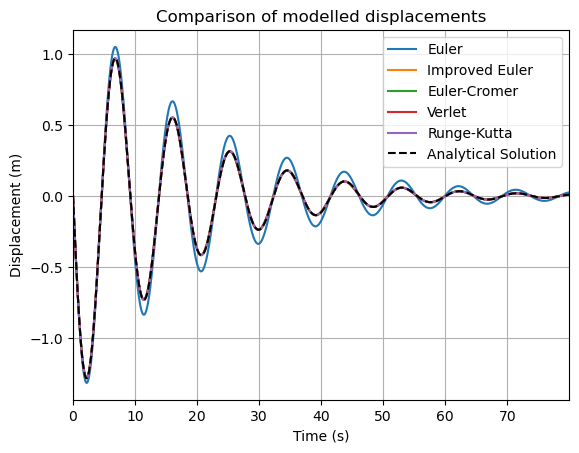

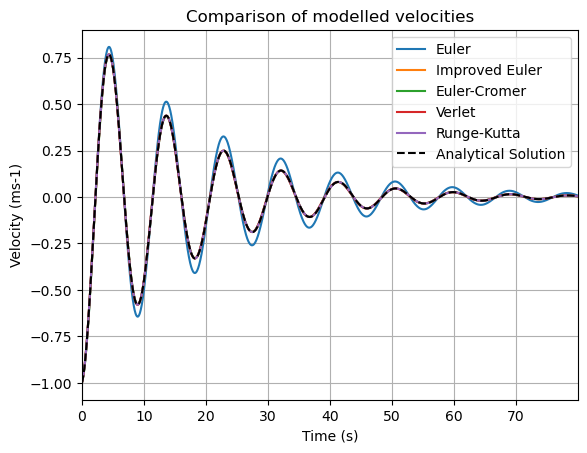

In [8]:
plt.figure()
plt.plot(E_t, E_x, label="Euler")
plt.plot(IE_t, IE_x, label="Improved Euler")
plt.plot(EC_t, EC_x, label="Euler-Cromer")
plt.plot(V_t, V_x, label="Verlet")
plt.plot(RK_t, RK_x, label="Runge-Kutta")
plt.plot(A_t, A_x, "k--", label="Analytical Solution")
plt.legend()
plt.title("Comparison of modelled displacements")
plt.xlabel("Time (s)")
plt.ylabel("Displacement (m)")
plt.margins(x=0)
plt.grid()

plt.figure()
plt.plot(E_t, E_v, label="Euler")
plt.plot(IE_t, IE_v, label="Improved Euler")
plt.plot(EC_t, EC_v, label="Euler-Cromer")
plt.plot(V_t, V_v, label="Verlet")
plt.plot(RK_t, RK_v, label="Runge-Kutta")
plt.plot(A_t, A_v, "k--", label="Analytical Solution")
plt.legend()
plt.title("Comparison of modelled velocities")
plt.xlabel("Time (s)")
plt.ylabel("Velocity (ms-1)")
plt.margins(x=0)
plt.grid()

plt.show()

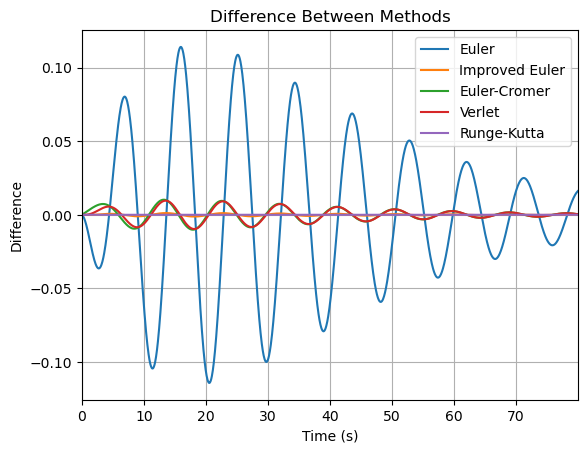

In [9]:
plt.figure()

plt.plot(E_t, E_x - A_x, label= "Euler")
plt.plot(IE_t, IE_x - A_x, label= "Improved Euler")
plt.plot(EC_t, EC_x - A_x, label= "Euler-Cromer")
plt.plot(V_t, V_x - A_x, label= "Verlet")
plt.plot(RK_t, RK_x - A_x, label= "Runge-Kutta")


plt.title("Difference Between Methods")
plt.xlabel("Time (s)")
plt.ylabel("Difference")
plt.legend()
plt.margins(x=0)
plt.grid()

plt.show()

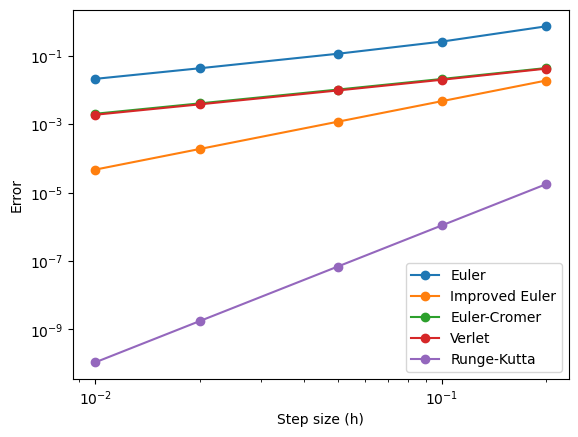

In [10]:
h_values = [0.2, 0.1, 0.05, 0.02, 0.01]

E_errors = []
IE_errors = []
EC_errors = []
V_errors = []
RK_errors = []

for h in h_values:
    
    E_x, E_v, E_t = Euler(T, h, x_0, v_0, k, m, b)
    IE_x, IE_v, IE_t = Improved_Euler(T, h, x_0, v_0, k, m, b)
    EC_x, EC_v, EC_t = Euler_Cromer(T, h, x_0, v_0, k, m, b)
    V_x, V_v, V_t = Verlet(T, h, x_0, v_0, k, m, b)
    RK_x, RK_v, RK_t = Runge_Kutta(T, h, x_0, v_0, k, m, b)
    
    A_x, A_v, A_t = analytical_sol(T, h, x_0, v_0, m, b, k)

    E_errors.append(np.max(np.abs(E_x - A_x)))
    IE_errors.append(np.max(np.abs(IE_x - A_x)))
    EC_errors.append(np.max(np.abs(EC_x - A_x)))
    V_errors.append(np.max(np.abs(V_x - A_x)))
    RK_errors.append(np.max(np.abs(RK_x - A_x)))

plt.loglog(h_values, E_errors, 'o-', label="Euler")
plt.loglog(h_values, IE_errors, 'o-', label="Improved Euler")
plt.loglog(h_values, EC_errors, 'o-', label="Euler-Cromer")
plt.loglog(h_values, V_errors, 'o-', label="Verlet")
plt.loglog(h_values, RK_errors, 'o-', label="Runge-Kutta")


plt.xlabel("Step size (h)")
plt.ylabel("Error")
plt.legend()
plt.show()

We can draw a conclusion from the figure above that the most accurate numerical intergration method is the Runge-Kutta. This is the expected conclusion as it is a 4-th order numerical integration method and its errors are to the power of 4. Out of the first 4 methods, it is shown that Improved Euler is the most accurate model. However, this is a non-symplectic method and so this report will outline its best method as Verlet.

Below is an investigation into the impact of changing values of damping on the errors.

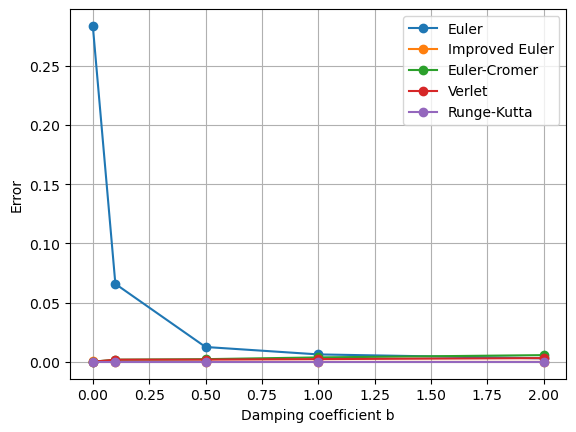

In [11]:
h = 0.01
b_values = [0, 0.1, 0.5, 1.0, 2.0]

E_errors = []
IE_errors = []
EC_errors = []
V_errors = []
RK_errors = []

for b_curr in b_values:
    
    E_x, E_v, E_t = Euler(T, h, x_0, v_0, k, m, b_curr)
    IE_x, IE_v, IE_t = Improved_Euler(T, h, x_0, v_0, k, m, b_curr)
    EC_x, EC_v, EC_t = Euler_Cromer(T, h, x_0, v_0, k, m, b_curr)
    V_x, V_v, V_t = Verlet(T, h, x_0, v_0, k, m, b_curr)
    RK_x, RK_v, RK_t = Runge_Kutta(T, h, x_0, v_0, k, m, b_curr)
    A_x, A_v, A_t = analytical_sol(T, h, x_0, v_0, m, b_curr, k)

    E_errors.append(np.max(np.abs(E_x - A_x)))
    IE_errors.append(np.max(np.abs(IE_x - A_x)))
    EC_errors.append(np.max(np.abs(EC_x - A_x)))
    V_errors.append(np.max(np.abs(V_x - A_x)))
    RK_errors.append(np.max(np.abs(RK_x - A_x)))

plt.plot(b_values, E_errors, 'o-', label="Euler")
plt.plot(b_values, IE_errors, 'o-', label="Improved Euler")
plt.plot(b_values, EC_errors, 'o-', label="Euler-Cromer")
plt.plot(b_values, V_errors, 'o-', label="Verlet")
plt.plot(b_values, RK_errors, 'o-', label="Runge-Kutta")

plt.xlabel("Damping coefficient b")
plt.ylabel("Error")
plt.legend()
plt.grid(True)
plt.show()

We can conclude that Euler breaks down at b=0. This conclusion is expected as Euler's method is non-sympletic so there is an absence of stablising friction which blows the system up. It creates a positive feedback loop that exponentially grows, that is normally surpressed by b > 0.

In [12]:
#Calculating max error made my code run faster, rather than running through all array values.
max_error_IE = np.max(np.abs(IE_x - A_x))
max_error_V = np.max(np.abs(V_x - A_x))
max_error_E = np.max(np.abs(E_x - A_x))
max_error_EC = np.max(np.abs(EC_x - A_x))
max_error_RK = np.max(np.abs(RK_x - A_x))

print("Improved Euler error:", max_error_IE)
print("Verlet error:", max_error_V)
print("Euler error:", max_error_E)
print("Euler-Cromer error:", max_error_EC)
print("Runge-Kutta error:", max_error_RK)

Improved Euler error: 8.764591492238516e-06
Verlet error: 0.0032135292596702225
Euler error: 0.003018206772778642
Euler-Cromer error: 0.005731527866276176
Runge-Kutta error: 1.3889653316390138e-11


This is an emphasis on the accuracy of the Runge-Kutta method. Whilst, the improved euler error is significantly small than the Verlet error, I believe that it is better suited to these specific conditions but blows up at b=0. Concluding Verlet is the best method and our focus for our investigations into effect of time-step and damping constant.

Week 2 : investigating impact of time-step

In [13]:
def plot_all_methods(h, quantity):
    m = 2.47
    k = 1.15
    b = 0.3
    T = 100
    x_0 = 0
    v_0 = -1

    methods = {"Euler": Euler, 
               "Euler-Cromer": Euler_Cromer,
               "Verlet": Verlet,
               "Improved Euler": Improved_Euler,
               "Runge-Kutta": Runge_Kutta}

    plt.figure(figsize=(8,5))
    for name, function in methods.items():
        x, v, t = function(T, h, x_0, v_0, k, m, b)
        if quantity == "Displacement":
            plt.plot(t, x, label=name)
        else:
            plt.plot(t, v, label=name)

    A_x, A_v, A_t = analytical_sol(T, h, x_0, v_0, m, b, k)
    if quantity == "Displacement":
        plt.plot(A_t, A_x, 'k--', label="Analytical")
        plt.ylabel("x(t) (m)")
    else:
        plt.plot(A_t, A_v, 'k--', label="Analytical")
        plt.ylabel("v(t) (m/s)")

    plt.xlabel("Time t (s)")
    plt.title(f"{quantity} with step size = {h:.3g}")
    plt.legend()
    plt.margins(x=0)
    plt.grid(True)
    plt.show()

interact(plot_all_methods, 
        h=FloatSlider(value=0.1, min=0.01, max=1.0, step=0.01, description="Step size"),
        quantity=Dropdown(options=["Displacement", "Velocity"], value="Displacement", description="Quantity"));

interactive(children=(FloatSlider(value=0.1, description='Step size', max=1.0, min=0.01, step=0.01), Dropdown(…

This clearly shows us that Euler blows up with large time steps and is very unstable. Verlet is very stable over time which solidifies our choice to define it as the best method for this report. At very small time-steps, *h*, the models are all accurate by observation but its errors are further investigated below to show its deviations from the analytical solution.

In [14]:
def plot_errors(h, T, b, quantity):
    
    m = 2.47
    k = 1.15
    x_0 = 0
    v_0 = -1

    methods = {
        "Euler": Euler,
        "Euler-Cromer": Euler_Cromer,
        "Verlet": Verlet,
        "Improved Euler": Improved_Euler,
        "Runge-Kutta": Runge_Kutta}

    A_x, A_v, A_t = analytical_sol(T, h, x_0, v_0, m, b, k)

    errors = {}
    for name, func in methods.items():
        x, v, t = func(T, h, x_0, v_0, k, m, b)
        if quantity == "Displacement":
            errors[name] = np.max(np.abs(x - A_x))
        else:
            errors[name] = np.max(np.abs(v - A_v))

    plt.figure(figsize=(8,5))
    plt.bar(errors.keys(), errors.values(), color=['C0','C1','C2','C3','C4'])
    plt.ylabel(f"Max absolute error ({quantity})")
    plt.title(f"Errors with h={h:.3g}, T={T}, b={b}")
    plt.grid()
    plt.show()

interact(
    plot_errors,
    h=FloatSlider(value=0.1, min=0.01, max=1, step=0.01, description="Step size 'h'"),
    T=FloatSlider(value=100, min=10, max=200, step=5, description="Integrating time 'T'"),
    b=FloatSlider(value=0.3, min=0.0, max=2, step=0.05, description="Damping constant 'b'"),
    quantity=Dropdown(options=["Displacement","Velocity"], value="Displacement", description="Quantity"));

interactive(children=(FloatSlider(value=0.1, description="Step size 'h'", max=1.0, min=0.01, step=0.01), Float…

The Runge-Kutta is extremely close to the analytical solution - its error is not zero but incredibly small. This is expected as it is a fourth order numerical integrator.

Below we will conduct an investigation into the effect of damping constant at three values. This is in respect to the critical damping value: $$b_{cr}^2 = 4km$$
We will plot three models: at half the critical damping value, at the critical damping value and double the critical damping.

In [15]:
b_cr = np.sqrt(4 * k * m)
print("The critical damping value is ", b_cr , ".")

The critical damping value is  3.3707565916274644 .


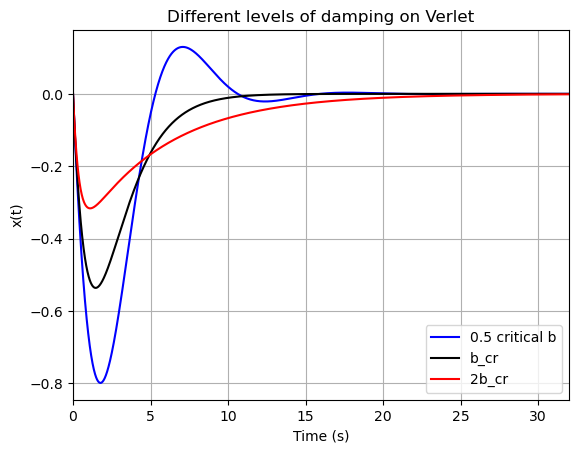

In [16]:
V_x1, V_v1, V_t1 = Verlet(32, h, x_0, v_0, k, m, 0.5 * b_cr)
V_x2, V_v2, V_t2 = Verlet(32, h, x_0, v_0, k, m, b_cr)
V_x3, V_v3, V_t3 = Verlet(32, h, x_0, v_0, k, m, 2 * b_cr)

plt.figure()
plt.plot(V_t1, V_x1, 'b', label="0.5 critical b")
plt.plot(V_t2, V_x2, 'k', label="b_cr")
plt.plot(V_t3, V_x3, 'r', label="2b_cr")
plt.xlabel("Time (s)")
plt.ylabel("x(t)")
plt.title("Different levels of damping on Verlet")
plt.margins(x=0)
plt.legend()
plt.grid()
plt.show()

At exactly critical damping, the system has exactly one oscillation but energy is dissipate quickly and unable to oscillate again. It doesn't overshoot the equilibrium point and comes to a rest.

At half critical damping, the system overshoots the equilibrium point and we can observe it completing almost two oscillations before coming to rest. A similar idea with double the critical damping value but the system is dissipates lots of energy and take a long time to return to the equilibrium point. The peak amplitudes for all three of these cases are lower than amplitudes at light/no damping.

In [17]:
def Verlet_push(T, h, x_0, v_0, k, m, b, F_0=0, push_time=0, duration=0):
    nsteps = int(T/h)
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    t = np.zeros(nsteps)
    
    x[0] = x_0 # in m
    v[0] = v_0 # in m . s-1

    for i in range(nsteps - 1):
        if push_time <= t[i] <= push_time + duration:
            F = F_0
        else:
            F = 0
            
        a_1 = (F / m) - (k / m) * x[i] - (b / m) * v[i]
        x_1 = x[i] + (v[i] * h)
        v_1 = v[i] + (a_1 * h)

        if push_time <= t[i] <= push_time + duration:
            next_F = F_0
        else:
            next_F = 0

        a_2 = (next_F / m) -(k / m) * x_1 - (b / m) * v_1
        x[i+1] = x[i] + 0.5 * (v[i] + v_1) * h
        v[i+1] = v[i] + 0.5 * (a_1 + a_2) * h
        t[i+1] = t[i] + h

    return x, v, t

In [18]:
def sinusoidalforce_V(T, h, x_0, v_0, k, m, b, F0=0, omega=0):
    nsteps = int(T / h)
    x = np.zeros(nsteps)
    v = np.zeros(nsteps)
    t = np.zeros(nsteps)
    
    x[0] = x_0
    v[0] = v_0
    
    for i in range(nsteps - 1):
        F = F0 * np.sin(omega * t[i])
        a_1 = (F / m) - (k / m) * x[i] - (b / m) * v[i]
        x_1 = x[i] + v[i] * h
        v_1 = v[i] + a_1 * h
        
        next_F = F0 * np.sin(omega * t[i+1])
        a_2 = (next_F / m) - (k / m) * x_1 - (b / m) * v_1
        x[i+1] = x[i] + 0.5 * (v[i] + v_1) * h
        v[i+1] = v[i] + 0.5 * (a_1 + a_2) * h
        t[i+1] = t[i] + h
        
    return x, v, t

x_forced, v_forced, t = sinusoidalforce_V(T, h, x_0, v_0, k, m, b, F0=5, omega=0.683)
x_unforced, v_unforced, _ = sinusoidalforce_V(T, h, x_0, v_0, k, m, b, F0=0)

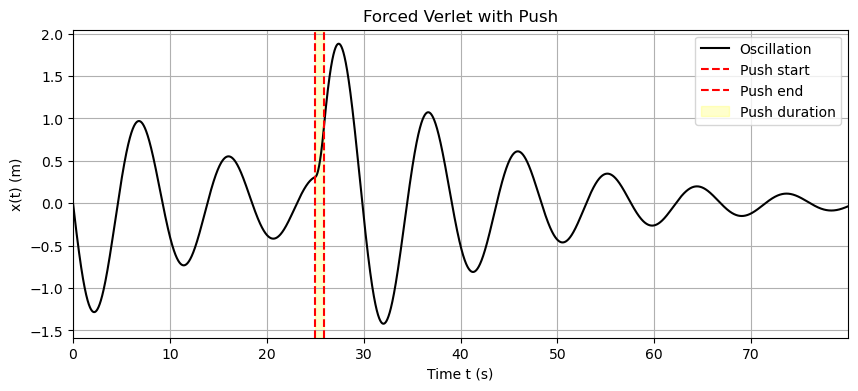

In [19]:
Forced_x1, Forced_v1, Forced_t1 = Verlet_push(T, h, x_0, v_0, k, m, b, F_0=4, push_time=25, duration=0.9)
push_time=25
duration=0.9

plt.figure(figsize=(10,4))
plt.plot(Forced_t1, Forced_x1, "k", label="Oscillation")
plt.axvline(push_time, color='r', linestyle='--', label='Push start')
plt.axvline(push_time + duration, color='r', linestyle='--', label='Push end')
plt.axvspan(push_time, push_time + duration, color='yellow', alpha=0.2, label='Push duration')
plt.xlabel("Time t (s)")
plt.ylabel("x(t) (m)")
plt.title("Forced Verlet with Push")
plt.grid(True)
plt.legend()
plt.margins(x=0)
plt.show()

Red dashed lines represent the start and end of push where the yellow shaded region is the duration. We can see that the model is damped until it is 'kicked' at t=25s and the amplitude is increased. After 0.9s, the model begins to reduce amplitude again due to light damping.

Below is a similar investigation, but substituting our 'kick' for generating a sinusoidal push at a constant frequency. The frequency can be altered but currently this function is set for the natural frequency of my system.

The natural frequency of my system is  9.199392836280506 .


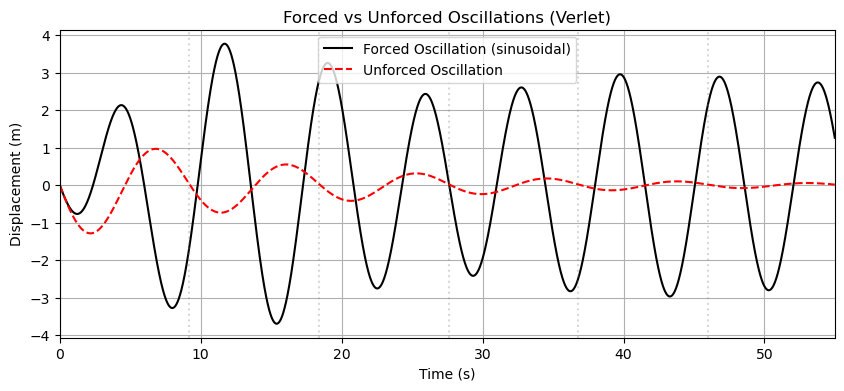

In [20]:
x_forced, v_forced, t = sinusoidalforce_V(T=55, h=h, x_0=x_0, v_0=v_0, k=k, m=m, b=b, F0=5, omega=0.9)
x_unforced, v_unforced, _ = sinusoidalforce_V(T=55, h=h, x_0=x_0, v_0=v_0, k=k, m=m, b=b, F0=0)

# Period at the natural frequency
T_0 = 2 * np.pi / 0.683
print("The natural frequency of my system is ", T_0, ".")

plt.figure(figsize=(10,4))
plt.plot(t, x_forced, "k", label='Forced Oscillation (sinusoidal)')
plt.plot(t, x_unforced, "red", label='Unforced Oscillation', linestyle='--')

for n in range(1, int(55 / T_0) + 1):
    plt.axvline(n*T_0, color='gray', linestyle=':', alpha=0.3)

plt.xlabel('Time (s)')
plt.ylabel('Displacement (m)')
plt.title('Forced vs Unforced Oscillations (Verlet)')
plt.grid(True)
plt.margins(x=0)
plt.legend()
plt.show()

Here, we have set the generated external sinusoidal frequency at the natural frequency of the system. At approximately 0.68rad/s. Here we see the expected response at resonant frequency. The force allows our amplitude to grow quicckly and this would continue until eventual mechanical breakdown in reality (or infinite growth for our model).

**Stretch yourself section: Investigating Resonance in our system**

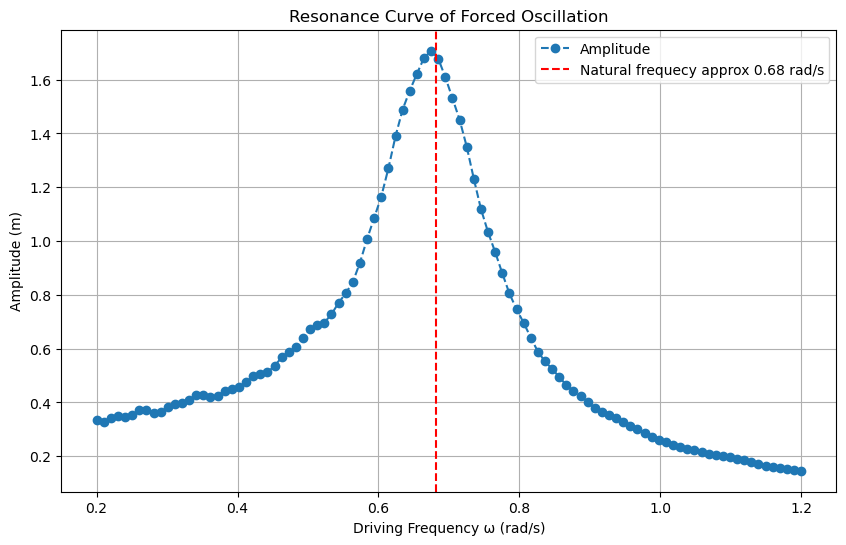

In [21]:
omega_n = np.sqrt(k / m)

# sweeping frequency below and above natural frequency
omega_vals = np.linspace(0.2, 1.2, 100)
amplitudes = []

for omega in omega_vals:
    x, v, t = sinusoidalforce_V(T, h, x_0, v_0, k, m, b, 1, omega)

    #the line below helps to ignore transient effects by taking the last 50% of the model
    remove_transient = x[len(x)//2:]
    #I also take the RMS to reduce noisy data
    amplitude = np.sqrt(np.mean(remove_transient**2))
    amplitudes.append(amplitude)         

#plotting the resonance curve
plt.figure(figsize=(10,6))
plt.plot(omega_vals, amplitudes, marker='o', linestyle='--', label='Amplitude')
plt.axvline(omega_n, color='r', linestyle='--', label=f'Natural frequecy approx {omega_n:.2f} rad/s')
plt.xlabel('Driving Frequency ω (rad/s)')
plt.ylabel('Amplitude (m)')
plt.title('Resonance Curve of Forced Oscillation')
plt.grid()
plt.legend()
plt.show()

Here we find our expected conclusions: the system shows resonant behaviour at the natural frequency that was calculated earlier (approx. 0.68rad/s). However, the peak is not sharp which represents damping is present in our system - again, as expected. The maximum amplitude also occurs slightly below our natural frequency which is what is expected in other models of damped oscillators.

**Final Conclusions**

This report was set out to model a damped harmonic oscillator using 4 numerical integration methods. A further extension for this report was comparing my results with a fourth-order numerical integration method - the Runge-Kutta. With further investigations into error from the analytical solution and with changing time step, we concluded the Runge-Kutta was the most accurate model.

The Improved Euler had the next smallest error, but with investigation of the impact of damping constant, we could conclude that it was unstable at b=0 as it is non-sympletic. This report focused its next investigation on Verlet as it was the most accurate, symplectic method.

We then investigated the impact of time-step on accuracy and took on a further investigation on the effect of varying damping constant. Verlet was stable for both ranges of time-step and damping constant. We then added force into the equation - via a 'kick' or an external sinusoidal frequency. This allowed us to investigated our system at resonant frequency. 

This was investigated further in the stretch yourself section. I took the last 50% of values and RMS to reduce noise and the system behaved as expected at resonance. We also took into account why the peak resonance differs slightly from the calculated natural frequency.